# 03_distilabel_judge_pipeline

-- RESOURCES
* [Install distilabel](https://distilabel.argilla.io/latest/sections/getting_started/installation/)
* [BasicPipeline](https://distilabel.argilla.io/dev/sections/how_to_guides/basic/pipeline/)
* [TextGeneration](https://distilabel.argilla.io/latest/components-gallery/tasks/textgeneration/?h=textgeneration#generate-text-from-an-instruction)
* [LLM classes](https://distilabel.argilla.io/latest/api/models/llm/llm_gallery/)

## Setup

In [ ]:
# Mount colab
if True:
    import os
    if not os.path.exists('/content/drive'):
        from google.colab import drive
        drive.mount('/content/drive')

# Paths
from pathlib import Path
PROJECT_ROOT: str = f"/content/drive/MyDrive/colab_notebooks/projects/trial_translator_project/v1.2"

Mounted at /content/drive


In [ ]:
# Install reqs
if True:
    %pip install -r {PROJECT_ROOT + "/requirements.txt"}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 612.9/612.9 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.4/177.4 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.2/511.2 kB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.7/141.7 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 358.8/358.8 kB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.5/83.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.1/278.1 kB 12.7 MB/s eta 0:00:00
  Attempting uninstall: jiter
    Found existing installation: jiter 0.13.0
    Uninstalling jiter-0.13.0:
      Successfully uninstalled jiter-0.13.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.7.1
    Uninstalling huggingface_hub-

In [ ]:
# -- env libraries --
import os
import sys
import importlib
import torch
import time
import ast
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint
from dataclasses import dataclass, asdict, field
from typing import List
from IPython.display import Image
sns.set_style("darkgrid")

# -- hugging face --
from datasets import load_dataset, Dataset

# -- distilabel --
from distilabel.models import LLM, LiteLLM
from distilabel.models.llms import VertexAILLM, GroqLLM
from distilabel.pipeline import Pipeline
from distilabel.steps import (
    LoadDataFromHub,
    LoadDataFromDicts,
    CombineOutputs,
    MergeColumns,
    GroupColumns,
    FormatChatGenerationDPO,
    FormatTextGenerationDPO,
    PreferenceToArgilla
)

# Add the PROJECT_ROOT directory to the Python path to import modules
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# -- project imports --
import src
from src.clients.llm_providers import check_available_models, check_my_limits
from src.utils import push_and_tag
from src.core import ThrottledTextGeneration, ThrottledUltraFeedback, CheckpointStep

# Reload all relevant modules
importlib.reload(src)
importlib.reload(src.clients.llm_providers)
importlib.reload(src.utils)
importlib.reload(src.core)

print("✅All relevant modules have been imported/reloaded.")

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'default' attribute with value None was provided to the `Field()` function, which has no effect in the context it was used. 'default' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(


✅All relevant modules have been imported/reloaded.


In [ ]:
# Config

@dataclass
class EnvConfig:
    seed: int = 42
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    is_kaggle: bool = False
    smoke_test: bool = False # If True, runs a quick test with a small subset of data instead of a full run.
    requires_keys: bool = True

@dataclass
class DataConfig:
    bronze_data_path: str = PROJECT_ROOT + "/data/clinical-trials-bronze-raw.csv"
    silver_data_path_local: str = PROJECT_ROOT + "/outputs/silver_generation_checkpoint.csv"
    silver_data_path_hub: str = "clinical-policy-silver-distill-cot"
    checkpoint_csv_path: str = PROJECT_ROOT + "/outputs/scored_silver_generation_checkpoint.csv"
    cot_dataset_name: str = "clinical-policy-scored-silver-distill-cot"
    load_from_hub: bool = True
    save_checkpoint_steps: int = 5
    dataset_version: str = "v1.0"
    checkpoint_logic: bool = True # If True, enables logic to skip already processed `nctIds` based on the checkpoint file.

@dataclass
class ModelConfig:
    # models_list: List[str] = field(default_factory=list)
    cot_instruction: str = ""
    llm_configs: List[LLM] = field(default_factory=list)
    judge_model: LLM = field(default_factory=lambda: LiteLLM(
        model="groq/openai/gpt-oss-120b", # Using a strong model as the judge
        generation_kwargs={
            "temperature": 0.1,
            "max_tokens": 2048,
            }
        )
    )
    add_judge_step: bool = False
    push_to_hub: bool = False

@dataclass
# NOTE: Use default_factory for mutable default values to prevent unintended shared state.
class CFG:
    env: EnvConfig = field(default_factory=EnvConfig)
    data: DataConfig = field(default_factory=DataConfig)
    model: ModelConfig = field(default_factory=ModelConfig)

    def __post_init__(self):
        """Runs automatically after the class is initialized."""
        # 1. Load keys (if necessary)
        if self.env.requires_keys:
            if self.env.is_kaggle:
                try:
                    from kaggle_secrets import UserSecretsClient
                    os.environ["REPO_ID"] = UserSecretsClient().get_secret("REPO_ID")
                    # os.environ["HUGGINGFACE_READ_TOKEN"] = UserSecretsClient().get_secret("HUGGINGFACE_READ_TOKEN")
                    os.environ["GOOGLE_API_KEY"] = UserSecretsClient().get_secret("GOOGLE_API_KEY")
                    os.environ["GROQ_API_KEY"] = UserSecretsClient().get_secret("GROQ_API_KEY")
                    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_WRITE_TOKEN")
                    print("✅ All Kaggle Secrets loaded.")
                except Exception as e:
                    print(f"ℹ️ Kaggle secrets not found or an error occurred: {e}")
            else:
                try:
                    from google.colab import userdata
                    os.environ["REPO_ID"] = userdata.get("REPO_ID")
                    # os.environ["HUGGINGFACE_READ_TOKEN"] = userdata.get("HUGGINGFACE_READ_TOKEN")
                    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
                    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
                    os.environ["HF_TOKEN"] = userdata.get("HF_WRITE_TOKEN")
                    print("✅ All Colab Userdata Secrets loaded.")
                except Exception as e:
                    print(f"ℹ️ Colab secrets not found or an error occurred: {e}")

    def to_dict(self):
        return asdict(self)

### Synthetic Data Generation Pipeline: Model Strategy

### 1. The Generators (Diversity of Thought)
To avoid "model collapse" in synthetic datasets, we use distinct architectures to provide a wider distribution of linguistic styles and logic paths:

* **Model A: `gemini/gemma-3-27b-it`**
    * **Role:** The Anchor. Gemma 3 provides state-of-the-art instruction following and reasoning in a 27B parameter dense format, serving as the high-efficiency baseline for the dataset.
* **Model B: `meta-llama/llama-4-scout-17b-16e-instruct`**
    * **Role:** The Creative. As a 16-expert Mixture-of-Experts (MoE) model, it generates a broader range of edge cases and nuanced variations than dense models.

### 2. The Judge (Quality Control)
The "Judge" must significantly exceed the intelligence of the generators to accurately identify hallucinations or low-quality outputs.

* **The Judge: `openai/gpt-oss-120b`**
    * **Role:** The Auditor. With 120B parameters, it possesses the "world knowledge" and reasoning depth required to audit the outputs of the 17B–32B generators.

---

### Summary Table

| Role | Model Choice | Key Strength for Synthetic Data |
| :--- | :--- | :--- |
| **Gen 1** | `Gemma 3 27B` | SOTA instruction following and reasoning. |
| **Gen 2** | `llama-4-scout` | Diversity of output via 16-expert MoE. |
| **Judge** | `gpt-oss-120b` | Superior auditing for filtering/scoring. |

In [ ]:
# Initialize config elements
data = DataConfig()
env = EnvConfig(
    smoke_test=True,
)
model = ModelConfig(
    judge_model=LiteLLM(
        model="groq/openai/gpt-oss-120b",
        generation_kwargs={
            "temperature": 0.0,
            "max_tokens": 2048,
            }
        ),
    add_judge_step = False,
    push_to_hub = True,
    llm_configs=[
        LiteLLM(
            model="gemini/gemma-3-27b-it",
            generation_kwargs={
                "temperature": 0.0,
                "max_tokens": 1024
                }
            ),
        LiteLLM(
            model="groq/meta-llama/llama-4-scout-17b-16e-instruct",
            generation_kwargs={
                "temperature": 0.0,
                "max_tokens": 1024
                }
            ),
        ],
    cot_instruction = '''
    You are an expert technical writer and researcher.
    Your task is to summarize the provided document for the specified target audience.

    FORMAT REQUIREMENTS:
    1. START your response immediately with the opening tag: <think>
    2. INSIDE THE <think> BLOCK:
      - Use plain text or Markdown bullet points only.
      - DO NOT use nested XML tags (e.g., do not use <key_facts>).
      - Address: 1) Key technical facts, 2) Implications for the audience, 3) Structural plan.
    3. END the reasoning section with the closing tag: </think>
    4. AFTER </think>, provide the final concise, professional report.

    CRITICAL RULES:
    - DO NOT wrap the tags or the response in Markdown code blocks (e.g., no ```xml or ```).
    - Output the raw tags <think> and </think> directly.
    - Ensure the final report is grounded 100% in the text.
    '''
    )

# Initialize config
config = CFG(data=data, env=env, model=model)
pprint(config.to_dict(), width=100)

✅ All Colab Userdata Secrets loaded.
{'data': {'bronze_data_path': '/content/drive/MyDrive/colab_notebooks/projects/trial_translator_project/v1.2/data/clinical-trials-bronze-raw.csv',
          'checkpoint_csv_path': '/content/drive/MyDrive/colab_notebooks/projects/trial_translator_project/v1.2/outputs/gold_generation_checkpoint.csv',
          'checkpoint_logic': True,
          'cot_dataset_name': 'clinical-policy-gold-distill-cot',
          'dataset_version': 'v1.0',
          'load_from_hub': True,
          'save_checkpoint_steps': 5,
          'silver_data_path_hub': 'clinical-policy-silver-distill-cot',
          'silver_data_path_local': '/content/drive/MyDrive/colab_notebooks/projects/trial_translator_project/v1.2/outputs/silver_generation_checkpoint.csv'},
 'env': {'device': 'cpu',
         'is_kaggle': False,
         'requires_keys': True,
         'seed': 42,
         'smoke_test': True},
 'model': {'add_judge_step': False,
           'cot_instruction': '\n'
             

## Data

In [ ]:
#@title Clean existing output data (if it does exist)
if True:
    temp_df = pd.read_csv(config.data.checkpoint_csv_path)
    if temp_df.isnull().values.any():
        user_input = input("ℹ️ Checkpoint CSV contains null values. Drop rows with nans? (y/n): ")
        if user_input.lower() == 'y':
            pd.read_csv(config.data.checkpoint_csv_path).dropna().to_csv(config.data.checkpoint_csv_path, index=False)
            print("Dropped rows with nans")
        else:
            print("Not dropping rows with nans")
    else:
        print("✅ Checkpoint CSV is clean.")

✅ Checkpoint CSV is clean.


### Load data

In [ ]:
if config.data.load_from_hub:
    print("ℹ️ Loading data from hub 🤗.")
    full_repo_id = f"{os.environ['REPO_ID']}/{config.data.silver_data_path_hub}"
    cot_ds = load_dataset(
        full_repo_id,
        split='train',
        revision="v1.2"
    )
else:
    print("ℹ️ Loading data from local.")
    cot_df = pd.read_csv(config.data.silver_data_path_local)
    cot_ds = Dataset.from_pandas(cot_df)

display(cot_ds.to_pandas().head())
display(cot_ds.shape)

ℹ️ Loading data from hub 🤗.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120 [00:00<?, ? examples/s]

,nctId,keyword,prompt,document,target_audience,generations,model_names,distilabel_metadata
0,NCT03935230,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Uncontrolled Donation After Circulatory...,Policy Makers,[<think>\n* Key technical facts: The document ...,"[gemini/gemma-3-27b-it, groq/meta-llama/llama-...",{'raw_input_generate_gemma_3_27b_it': [{'conte...
1,NCT02501681,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Evaluation of Different Priming Solutio...,Policy Makers,[<think>\n* Key technical facts: This is a sin...,"[gemini/gemma-3-27b-it, groq/meta-llama/llama-...",{'raw_input_generate_gemma_3_27b_it': [{'conte...
2,NCT02270242,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Ticagrelor With Aspirin or Alone in Hig...,Policy Makers,[<think>\n* Key technical facts: The study com...,"[gemini/gemma-3-27b-it, groq/meta-llama/llama-...",{'raw_input_generate_gemma_3_27b_it': [{'conte...
3,NCT05543096,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: PMCF Study for Cardiology Access Proced...,Policy Makers,[<think>\n* Key technical facts: This is a ret...,"[gemini/gemma-3-27b-it, groq/meta-llama/llama-...",{'raw_input_generate_gemma_3_27b_it': [{'conte...
4,NCT02802696,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Transfusion-Associated Circulatory Over...,Policy Makers,[<think>\n* Key technical facts: This is a pil...,"[gemini/gemma-3-27b-it, groq/meta-llama/llama-...",{'raw_input_generate_gemma_3_27b_it': [{'conte...


(120, 8)

### Token checks

In [ ]:
metadata = pd.json_normalize(
    cot_ds['distilabel_metadata']
)

# Identify all input and output token columns
input_token_cols = [col for col in metadata.columns if 'input_tokens' in col]
output_token_cols = [col for col in metadata.columns if 'output_tokens' in col]

# Sum input tokens (if any), counting the prompt only once.
total_input_tokens = metadata[input_token_cols[0]].fillna(0) if input_token_cols else pd.Series(0, index=metadata.index)

# Sum all output tokens across all models.
total_output_tokens = metadata[output_token_cols].sum(axis=1).fillna(0) if output_token_cols else pd.Series(0, index=metadata.index)

# Calculate total tokens
metadata['total_tokens'] = total_input_tokens + total_output_tokens

print(" -- Total tokens statistics  -- ")
display(
    metadata['total_tokens']
    .describe()
    .to_frame()
    .T
    )
print(f"Total tokens: {metadata['total_tokens'].sum()}")

 -- Total tokens statistics  -- 


,count,mean,std,min,25%,50%,75%,max
total_tokens,120.0,1532.133333,294.073275,1026.0,1292.0,1482.0,1739.75,2396.0


Total tokens: 183856


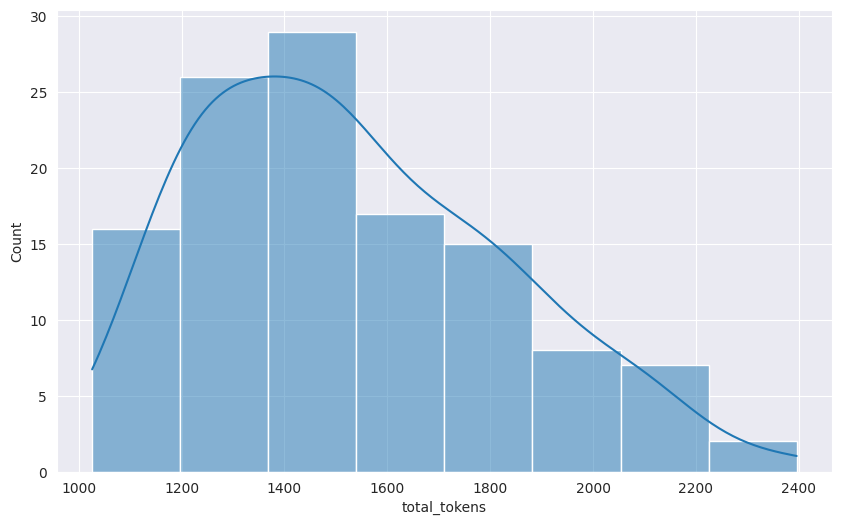

In [ ]:
# Visualize the token distribution
plt.figure(figsize=(10, 6))
ax = sns.histplot(
    metadata['total_tokens'],
    kde=True,
)
plt.show()

### **Phase 2: LLM-as-a-Judge (Evaluation Strategy)**

To transform the "Silver" generations into a high-quality "Scored-Silver" dataset, we employ an **UltraFeedback** ranking protocol using GPT as a neutral evaluator.

#### **1. Token Profile Analysis**
Based on the Silver dataset statistics (combined instruction + 2 outputs), the Judge step handles significantly denser payloads:
* **Count:** 120 Trials
* **Mean Input:** 1,532 tokens
* **Max Input:** 2,396 tokens
* **Total Dataset Volume:** ~184,000 tokens.

#### **2. Rationale: Choosing GPT over Llama-3.3-70B**
* **Bias Mitigation:** We intentionally avoid "Self-Preference Bias" by using a non-Meta model to judge the outputs of `Llama-4-Scout`. A cross-provider judge (OpenAI) ensures evaluation is based on clinical accuracy rather than stylistic familiarity with the Llama architecture.
* **The Intelligence Ceiling:** The judge must act as the "Teacher." GPT-4o provides a higher reasoning ceiling for complex policy comparisons than 70B-class open-weights models, which is crucial for identifying nuanced errors in clinical reasoning.

#### **3. Throttling & Throughput Optimization**
The GPT Tier (8k TPM / 30 RPM) presents a strict **token bottleneck** rather than a request bottleneck.
* **Constraint:** 8,000 Tokens Per Minute (TPM).
* **Strategy:** **Sequential Drip-Feeding** with a strict **15.0s delay**.
* **Calculated Load:** $4 \text{ RPM} \times 1,532 \text{ (mean)} = 6,128 \text{ TPM}$.
* **Headroom:** This ~23% buffer (1,872 tokens) protects the pipeline from `429` errors during high-token "Max" trial scenarios where a single request hits ~2.4k tokens.



## Judge Pipeline

In [ ]:
#@title Check available models and current limits of selected ones
check_available_models()

print("\n-- Model (and provider) selected as judge: --")
print(config.model.judge_model.model_name.split("/", maxsplit=1))
provider, model = config.model.judge_model.model_name.split("/", maxsplit=1)
check_my_limits(provider, model)

=========================GOOGLE MODELS=========================
models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-3-1b-it
models/gemma-3-4b-it
models/gemma-3-12b-it
models/gemma-3-27b-it
models/gemma-3n-e4b-it
models/gemma-3n-e2b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-2.5-flash-lite-preview-09-2025
models/gemini-3-pro-preview
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3-pro-image-preview
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/gemini-robotics-er-1.5-preview
models/gemini-2.5-compu

### Define Pipeline

In [ ]:
# Drop row from dictionary if the scored_silver_checkpoint exists and it has already got a row with the same nctId
push_distiset = True # Assume full run by default

if os.path.isfile(config.data.checkpoint_csv_path):
    scored_silver_checkpoint = pd.read_csv(config.data.checkpoint_csv_path)
    print("ℹ️ Checkpoint CSV found and loaded.")

    existing_nctIds = scored_silver_checkpoint['nctId'].to_list()
    if existing_nctIds:
        cot_ds = cot_ds.filter(lambda x: x['nctId'] not in existing_nctIds)
        push_distiset = False # Not a full run, as some data was filtered out
        print(
              f"Current rows: {len(cot_ds)}"
              f"\nRows dropped: {len(existing_nctIds)}"
            )
else:
    print("ℹ️ No scored_silver_checkpoint found.")

ℹ️ Checkpoint CSV found and loaded.


Filter:   0%|          | 0/120 [00:00<?, ? examples/s]

Current rows: 0
Rows dropped: 120


In [ ]:
with Pipeline(name="Judge-Pipeline") as judge_pipeline:

    # NOTE: flip the flag to True if processing the whole dataset at once
    # (i.e., no need for checkpoint logic like checking unique nctIds)
    if config.data.load_from_hub and not config.data.checkpoint_logic:
        loader = LoadDataFromHub(
            repo_id=full_repo_id,
            batch_size=50,
        )
    else:
        loader = LoadDataFromDicts(
            data=cot_ds.to_list(),
            batch_size=50
        )

    ranker = ThrottledUltraFeedback(
        name="ultrafeedback_ranking",
        llm=config.model.judge_model,
        input_batch_size=1, # ⚠️ IMPORTANT FOR RPM/TPM RATE LIMITS
        aspect="overall-rating",
        input_mappings={
            "instruction": "prompt",
            "generations": "generations",
        },
        use_default_structured_output=True,
        output_mappings={
            "model_name": "judge_model",
            "ratings": "ratings",
            "rationales": "rationales"
        }
    )

    saver = CheckpointStep(
        name="checkpoint_save",
        file_path=config.data.checkpoint_csv_path,
        input_batch_size=config.data.save_checkpoint_steps
        )

    loader >> ranker >> saver

### Distilabel "Batch Size" Decoder & Recommendations

When running a **Judge Pipeline** with strict API rate limits, use these settings to balance efficiency and reliability.

| Parameter | Location | Purpose | Recommended Value |
| :--- | :--- | :--- | :--- |
| **`batch_size`** | `GeneratorStep` (e.g., LoadDataFromHub) | **The Plumbing:** How many rows are pulled from the source into the pipeline's internal queue at once. | **50 - 100** |
| **`dataset_batch_size`** | `Pipeline.run()` | **The Factory Floor:** How many total rows are allowed to be "in flight" across the entire DAG before the loader pauses. | **50+** |
| **`input_batch_size`** | `Task` (e.g., ThrottledUltraFeedback) | **The Throttle:** How many rows this specific worker takes to process in one `process()` call. | **1** (Forces 1 row = 1 sleep) |
| **`input_batch_size`** | `Step` (e.g., CheckpointStep) | **The Safety Net:** How many processed rows must accumulate before they are physically written to the CSV. | **1 - 5** |

---

1.  **`UltraFeedback(input_batch_size=1)`**: This is the most critical setting. It ensures your `ThrottledUltraFeedback` class executes the `time.sleep` for **every single row**, preventing 429 Rate Limit errors.
2.  **`CheckpointStep(input_batch_size=5)`**: By setting this to a low number, you ensure that if the notebook/pipeline crashes, you don't lose all the work.
3.  **`Pipeline.run(dataset_batch_size=50)`**: This allows the pipeline to keep a healthy buffer of rows ready, ensuring the "plumbing" isn't the bottleneck—only your API-limited Judge is.


In [ ]:
# Draw pipeline
try:
  image_file = judge_pipeline.draw()
  display(Image(image_file))
except Exception as e:
  print(f"Failed to draw pipeline graph: {e}")

Failed to draw pipeline graph: list index out of range


In [ ]:
# EXECUTE
config.env.smoke_test = False
if __name__ == "__main__":
  if config.env.smoke_test:
      print("ℹ️Smoke-test run")
      distiset = judge_pipeline.dry_run()
  else:
      print("Full run")
      distiset = judge_pipeline.run(
          dataset_batch_size=50,
      )

Full run


[03/26/26 18:30:31] INFO     ['distilabel.pipeline'] 📝 Pipeline data will be written to               ]8;id=440699;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py\base.py]8;;\:]8;id=626399;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py#1015\1015]8;;\
                             '/root/.cache/distilabel/pipelines/Judge-Pipeline/cd4ae1da122d9bb059a53f3             
                             9a95b18e98378ad75/executions/cd47b53f02f7b133d9648fa0b4d891ff59b3933a/dat             
                             a/steps_outputs'                                                                      

                    INFO     ['distilabel.pipeline'] ⌛ The steps of the pipeline will be loaded in    ]8;id=375592;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py\base.py]8;;\:]8;id=670267;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py#1046\1046]8;;\
                             stages:                                                                               
                              * Legend: 🚰 GeneratorStep 🌐 GlobalStep 🔄 Step                                     
                              * Stage 0:                                                                           
                                - 🚰 'load_data_from_dicts_0'                                                      
                                - 🔄 'ultrafeedback_ranking'                                                       
                                - 🔄 'checkpoint_save'                                                             

                    INFO     ['distilabel.pipeline'] ⏳ Waiting for all the steps of stage 0 to        ]8;id=97602;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py\base.py]8;;\:]8;id=236399;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py#1382\1382]8;;\
                             load...                                                                               

[03/26/26 18:30:33] INFO     ['distilabel.pipeline'] ⏳ Steps from stage 0 loaded: 2/3                 ]8;id=315411;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py\base.py]8;;\:]8;id=287409;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/base.py#1418\1418]8;;\
                              * 'load_data_from_dicts_0' replicas: 1/1                                             
                              * 'ultrafeedback_ranking' replicas: 0/1                                              
                              * 'checkpoint_save' replicas: 1/1                                                    

/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


... (10 outputs left out)

                    INFO     ['distilabel.step.checkpoint_save'] 📦 Processing batch 0 in       ]8;id=39944;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py\step_wrapper.py]8;;\:]8;id=404724;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py#230\230]8;;\
                             'checkpoint_save' (replica ID: 0)                                                     

                    INFO     ['distilabel.step.checkpoint_save'] 📨 Step 'checkpoint_save'      ]8;id=77751;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py\step_wrapper.py]8;;\:]8;id=491508;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py#290\290]8;;\
                             sending batch 0 to output queue                                                       

                    INFO     ['distilabel.step.checkpoint_save'] 🏁 Finished running step       ]8;id=658362;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py\step_wrapper.py]8;;\:]8;id=451359;file:///usr/local/lib/python3.12/dist-packages/distilabel/pipeline/step_wrapper.py#129\129]8;;\
                             'checkpoint_save' (replica ID: 0)                                                     

Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
# Push distiset directly if done in one run (full data), else push full data from local path
local_checkpoint_ds = Dataset.from_csv(config.data.checkpoint_csv_path)
push_distiset = False

if config.model.push_to_hub:
    repo_id = f"{os.environ['REPO_ID']}/{config.data.cot_dataset_name}"
    push_and_tag(
        distiset if push_distiset else Dataset.from_csv(config.data.checkpoint_csv_path),
        repo_id,
        commit_msg="Uploading synthetic distilled CoT dataset.",
        artifact_type="dataset",
        version_tag=config.data.dataset_version
    )

ℹ️Pushing to Francesco-A/clinical-policy-gold-distill-cot


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  56%|#####5    |  537kB /  959kB            

Creating tag v1.0
✅Done!


# OTHER (type fix)
> ℹ️ Note to self: next time use parquet rather than csv for saving artifacts/checkpoints

In [ ]:
# distiset['default']['train'].to_pandas().explode('ratings')
Dataset.from_csv(config.data.checkpoint_csv_path).to_pandas().explode('ratings')

,nctId,keyword,prompt,document,target_audience,generations,model_names,distilabel_metadata,ratings,rationales,judge_model
0,NCT01633502,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Danish Cardiogenic Shock Trial\n\nSUMMA...,Policy Makers,['<think>\n* Key technical facts: Cardiogenic ...,"['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 4]","['Text 1 follows all formatting rules, provide...",groq/openai/gpt-oss-120b
1,NCT01282203,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Evaluation of Volatile Induction and Ma...,Policy Makers,['<think>\n* Key technical facts: This is a po...,"['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]","['Text 1 follows all formatting rules, provide...",groq/openai/gpt-oss-120b
2,NCT02436421,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Impact of Best Practice Alerts in Cardi...,Policy Makers,['<think>\n* Key technical facts: The study im...,"['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]","['Text 1 follows all formatting rules, present...",groq/openai/gpt-oss-120b
3,NCT03935230,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Uncontrolled Donation After Circulatory...,Policy Makers,['<think>\n* Key technical facts: The document...,"['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]",['Text 1 follows the required <think> tag form...,groq/openai/gpt-oss-120b
4,NCT02501681,Cardiovascular,INSTRUCTION: \n You are an expert technical...,TITLE: Evaluation of Different Priming Solutio...,Policy Makers,"[""<think>\n* Key technical facts: This is a si...","['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]","['Text 1 follows all formatting rules, provide...",groq/openai/gpt-oss-120b
...,...,...,...,...,...,...,...,...,...,...,...
115,NCT00160979,Oncology,INSTRUCTION: \n You are an expert technical...,TITLE: Transrectal Tumour Oxygen - US Army\n\n...,Policy Makers,['<think>\n* Key technical facts:\n * Prost...,"['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[4, 5]",['Text 1 follows formatting rules and provides...,groq/openai/gpt-oss-120b
116,NCT01251666,Oncology,INSTRUCTION: \n You are an expert technical...,"TITLE: Comparison of Hemoccult, Magstream and ...",Policy Makers,"[""<think>\n* Key technical facts: This study c...","['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]","['Text 1 follows all formatting rules, provide...",groq/openai/gpt-oss-120b
117,NCT03731247,Oncology,INSTRUCTION: \n You are an expert technical...,TITLE: Optical Coherence Microscopy in Dermato...,Policy Makers,"[""<think>\n* Key technical facts: The OCTAV de...","['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 5]","['Text 1 follows all formatting rules, provide...",groq/openai/gpt-oss-120b
118,NCT02799524,Oncology,INSTRUCTION: \n You are an expert technical...,TITLE: Comparison of Mood Disorders Screening ...,Policy Makers,"[""<think>\n* Key technical facts: The study co...","['gemini/gemma-3-27b-it', 'groq/meta-llama/lla...","{'raw_output_ultrafeedback_ranking': '{""rating...","[5, 3]",['Text 1 fully complies with the required <thi...,groq/openai/gpt-oss-120b


### Fixing and Re-pushing the Gold Dataset

To correct the data types in the 'scored_silver' dataset already pushed to the Hugging Face Hub, we need to:

1.  Load the existing 'scored_silver' dataset from the Hub.
2.  Identify the columns that should contain lists or dictionaries but are currently strings.
3.  Apply `ast.literal_eval` to these columns to convert their string representations into actual Python objects.
4.  Push the corrected dataset back to the Hugging Face Hub with a new version tag (e.g., `v1.1`) to differentiate it from the previous, incorrectly typed version. Overwriting existing tags is generally discouraged unless strictly necessary, so a new tag is safer.

In [ ]:
import ast
from datasets import load_dataset, Dataset
from huggingface_hub import create_tag
import os

# Define the full repository ID for the scored_silver dataset
repo_id = f"{os.environ['REPO_ID']}/{config.data.cot_dataset_name}"

print(f"ℹ️ Loading existing scored_silver dataset from: {repo_id}")
# Load the existing scored_silver dataset from the Hub
current_scored_silver_ds = load_dataset(
    repo_id,
    split='train', # Assuming 'train' split
    revision=config.data.dataset_version # Load the specific version that needs fixing
)

# Convert to pandas DataFrame for easier type manipulation
current_scored_silver_df = current_scored_silver_ds.to_pandas()

# Define columns that should be lists/dicts (based on previous observations)
# These are the same as `explode_cols` and `reformat_cols` from previous steps
reformat_cols = ['generations', 'model_names', 'ratings', 'rationales', 'distilabel_metadata']

print("ℹ️ Reformatting columns to Python objects...")
# Apply ast.literal_eval to convert string representations to actual Python objects
for col in reformat_cols:
    if col in current_scored_silver_df.columns:
        print(f"  - Processing column: '{col}' (current type: {current_scored_silver_df[col].dtype})")
        # Use ast.literal_eval, handling potential NaNs gracefully
        current_scored_silver_df[col] = current_scored_silver_df[col].apply(
            lambda x: ast.literal_eval(x) if isinstance(x, str) and (x.startswith('[') or x.startswith('{')) else x
        )
        print(f"    --> Fixed type: {current_scored_silver_df[col].apply(type).iloc[0] if not current_scored_silver_df[col].empty else 'empty'}")

# Convert back to Dataset object
corrected_scored_silver_ds = Dataset.from_pandas(current_scored_silver_df)

# Increment the version tag (e.g., v1.0 -> v1.1)
new_version_tag = "v" + str(float(config.data.dataset_version.replace('v', '')) + 0.1)
print(f"ℹ️ Pushing corrected dataset to {repo_id} with new tag: {new_version_tag}")

# Push the corrected dataset to the Hugging Face Hub
corrected_scored_silver_ds.push_to_hub(
    repo_id,
    private=False,
    commit_message=f"Corrected data types for version {new_version_tag}"
)

# Create a new version tag
create_tag(
    repo_id=repo_id,
    tag=new_version_tag,
    repo_type="dataset",
    tag_message=f"Release of {new_version_tag} with corrected data types"
)
print("✅ Done! Corrected dataset pushed with new tag.")

# Update the config to use the new version going forward if desired
# config.data.dataset_version = new_version_tag

ℹ️ Loading existing gold dataset from: Francesco-A/clinical-policy-gold-distill-cot
ℹ️ Reformatting columns to Python objects...
  - Processing column: 'generations' (current type: object)
    --> Fixed type: <class 'list'>
  - Processing column: 'model_names' (current type: object)
    --> Fixed type: <class 'list'>
  - Processing column: 'ratings' (current type: object)
    --> Fixed type: <class 'list'>
  - Processing column: 'rationales' (current type: object)
    --> Fixed type: <class 'list'>
  - Processing column: 'distilabel_metadata' (current type: object)
    --> Fixed type: <class 'dict'>
ℹ️ Pushing corrected dataset to Francesco-A/clinical-policy-gold-distill-cot with new tag: v1.1


## Requirements

In [ ]:
!pip freeze

absl-py==1.4.0
accelerate==1.13.0
access==1.1.10.post3
affine==2.4.0
aiofiles==24.1.0
aiohappyeyeballs==2.6.1
aiohttp==3.13.3
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.11.2
alembic==1.18.4
altair==5.5.0
annotated-doc==0.0.4
annotated-types==0.7.0
antlr4-python3-runtime==4.9.3
anyio==4.12.1
anywidget==0.9.21
apsw==3.51.3.0
apswutils==0.1.2
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
array_record==0.8.3
arrow==1.4.0
arviz==0.22.0
astropy==7.2.0
astropy-iers-data==0.2026.3.16.0.53.33
astunparse==1.6.3
atpublic==5.1
attrs==25.4.0
audioread==3.1.0
Authlib==1.6.9
autograd==1.8.0
babel==2.18.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b6
bigframes==2.38.0
bigquery-magics==0.10.3
bleach==6.3.0
blinker==1.9.0
blis==1.3.3
blobfile==3.2.0
blosc2==4.1.2
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.45
branca==0.8.2
brotli==1.2.0
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.2.25
c

```markdown
absl-py==1.4.0
accelerate==1.13.0
access==1.1.10.post3
affine==2.4.0
aiofiles==24.1.0
aiohappyeyeballs==2.6.1
aiohttp==3.13.3
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.11.2
alembic==1.18.4
altair==5.5.0
annotated-doc==0.0.4
annotated-types==0.7.0
antlr4-python3-runtime==4.9.3
anyio==4.12.1
anywidget==0.9.21
apsw==3.51.3.0
apswutils==0.1.2
argon2-cffi==25.1.0
argon2-cffi-bindings==25.1.0
array_record==0.8.3
arrow==1.4.0
arviz==0.22.0
astropy==7.2.0
astropy-iers-data==0.2026.3.16.0.53.33
astunparse==1.6.3
atpublic==5.1
attrs==25.4.0
audioread==3.1.0
Authlib==1.6.9
autograd==1.8.0
babel==2.18.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b6
bigframes==2.38.0
bigquery-magics==0.10.3
bleach==6.3.0
blinker==1.9.0
blis==1.3.3
blobfile==3.2.0
blosc2==4.1.2
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.45
branca==0.8.2
brotli==1.2.0
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.2.25
cffi==2.0.0
chardet==5.2.0
charset-normalizer==3.4.6
clarabel==0.11.1
click==8.3.1
click-plugins==1.1.1.2
cligj==0.7.2
cloudpathlib==0.23.0
cloudpickle==3.1.2
cmake==3.31.10
cmdstanpy==1.3.0
colorcet==3.1.0
colorlover==0.3.0
colour==0.1.5
community==1.0.0b1
confection==0.1.5
cons==0.4.7
contourpy==1.3.3
cramjam==2.11.0
cryptography==43.0.3
cufflinks==0.17.3
curl_cffi==0.14.0
cvxopt==1.3.2
cvxpy==1.6.7
cycler==0.12.1
cyipopt==1.5.0
cymem==2.0.13
Cython==3.0.12
dask==2026.1.2
dataproc-spark-connect==1.0.2
datasets==4.0.0
db-dtypes==1.5.0
dbus-python==1.2.18
debugpy==1.8.15
decorator==4.4.2
defusedxml==0.7.1
deprecation==2.1.0
diffusers==0.37.0
dill==0.3.8
diskcache==5.6.3
distilabel==1.5.3
distro==1.9.0
dlib==19.24.6
dm-tree==0.1.9
docstring_parser==0.17.0
docutils==0.21.2
dopamine_rl==4.1.2
duckdb==1.3.2
earthengine-api==1.5.24
easydict==1.13
editdistance==0.8.1
eerepr==0.1.2
einops==0.8.2
en_core_web_sm @ https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl#sha256=1932429db727d4bff3deed6b34cfc05df17794f4a52eeb26cf8928f7c1a0fb85
entrypoints==0.4
esda==2.8.2
et_xmlfile==2.0.0
etils==1.14.0
etuples==0.3.10
Farama-Notifications==0.0.4
fastai==2.8.7
fastapi==0.135.1
fastcore==1.12.26
fastdownload==0.0.7
fastjsonschema==2.21.2
fastlite==0.2.4
fastprogress==1.1.5
fasttransform==0.0.2
fastuuid==0.14.0
ffmpy==1.0.0
filelock==3.25.2
fiona==1.10.1
firebase-admin==6.9.0
Flask==3.1.3
flatbuffers==25.12.19
flax==0.11.2
folium==0.20.0
fonttools==4.62.1
fqdn==1.5.1
frozendict==2.4.7
frozenlist==1.8.0
fsspec==2025.3.0
future==1.0.0
gast==0.7.0
gcsfs==2025.3.0
GDAL==3.8.4
gdown==5.2.1
geemap==0.35.3
geocoder==1.38.1
geographiclib==2.1
geopandas==1.1.3
geopy==2.4.1
giddy==2.3.8
gin-config==0.5.0
gitdb==4.0.12
GitPython==3.1.46
glob2==0.7
google==3.0.0
google-adk==1.27.1
google-ai-generativelanguage==0.6.15
google-api-core==2.30.0
google-api-python-client==2.192.0
google-auth==2.47.0
google-auth-httplib2==0.3.0
google-auth-oauthlib==1.3.0
google-cloud-aiplatform==1.141.0
google-cloud-appengine-logging==1.8.0
google-cloud-audit-log==0.4.0
google-cloud-bigquery==3.40.1
google-cloud-bigquery-connection==1.20.0
google-cloud-bigquery-storage==2.36.2
google-cloud-bigtable==2.35.0
google-cloud-core==2.5.0
google-cloud-dataplex==2.16.0
google-cloud-dataproc==5.25.0
google-cloud-datastore==2.23.0
google-cloud-discoveryengine==0.13.12
google-cloud-firestore==2.25.0
google-cloud-functions==1.22.0
google-cloud-iam==2.21.0
google-cloud-language==2.19.0
google-cloud-logging==3.14.0
google-cloud-monitoring==2.29.1
google-cloud-pubsub==2.36.0
google-cloud-resource-manager==1.16.0
google-cloud-secret-manager==2.26.0
google-cloud-spanner==3.63.0
google-cloud-speech==2.37.0
google-cloud-storage==3.9.0
google-cloud-trace==1.18.0
google-cloud-translate==3.24.0
google-colab @ file:///colabtools/dist/google_colab-1.0.0.tar.gz
google-crc32c==1.8.0
google-genai==1.67.0
google-generativeai==0.8.6
google-pasta==0.2.0
google-resumable-media==2.8.0
googleapis-common-protos==1.73.0
googledrivedownloader==1.1.0
gradio==5.50.0
gradio_client==1.14.0
grain==0.2.16
graphviz==0.21
greenlet==3.3.2
groovy==0.1.2
groq==1.1.2
grpc-google-iam-v1==0.14.3
grpc-interceptor==0.15.4
grpcio==1.78.0
grpcio-status==1.71.2
grpclib==0.4.9
gspread==6.2.1
gspread-dataframe==4.0.0
gym==0.25.2
gym-notices==0.1.0
gymnasium==1.2.3
h11==0.16.0
h2==4.3.0
h5netcdf==1.8.1
h5py==3.16.0
hdbscan==0.8.41
hf-xet==1.4.2
highspy==1.13.1
holidays==0.93
holoviews==1.22.1
hpack==4.1.0
html5lib==1.1
httpcore==1.0.9
httpimport==1.4.1
httplib2==0.31.2
httptools==0.7.1
httpx==0.28.1
httpx-sse==0.4.3
huggingface_hub==1.6.0
humanize==4.15.0
hyperframe==6.1.0
hyperopt==0.2.7
ibis-framework==9.5.0
idna==3.11
ImageIO==2.37.3
imageio-ffmpeg==0.6.0
imagesize==2.0.0
imbalanced-learn==0.14.1
immutabledict==4.3.1
importlib_metadata==8.7.1
importlib_resources==6.5.2
imutils==0.5.4
inequality==1.1.2
inflect==7.5.0
iniconfig==2.3.0
instructor==1.14.5
intel-cmplr-lib-ur==2025.3.2
intel-openmp==2025.3.2
ipyevents==2.0.4
ipyfilechooser==0.6.0
ipykernel==6.17.1
ipyleaflet==0.20.0
ipyparallel==8.8.0
ipython==7.34.0
ipython-genutils==0.2.0
ipython-sql==0.5.0
ipytree==0.2.2
ipywidgets==7.7.1
isoduration==20.11.0
itsdangerous==2.2.0
jaraco.classes==3.4.0
jaraco.context==6.1.1
jaraco.functools==4.4.0
jax==0.7.2
jaxlib==0.7.2
jeepney==0.9.0
jieba==0.42.1
Jinja2==3.1.6
jiter==0.11.1
joblib==1.5.3
jsonpatch==1.33
jsonpickle==4.1.1
jsonpointer==3.0.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter-console==6.6.3
jupyter-events==0.12.0
jupyter-leaflet==0.20.0
jupyter_client==7.4.9
jupyter_core==5.9.1
jupyter_kernel_gateway @ git+https://github.com/googlecolab/kernel_gateway@b134e9945df25c2dcb98ade9129399be10788671
jupyter_server==2.14.0
jupyter_server_terminals==0.5.4
jupyterlab_pygments==0.3.0
jupyterlab_widgets==3.0.16
jupytext==1.19.1
kaggle==2.0.0
kagglehub==1.0.0
kagglesdk==0.1.16
keras==3.13.2
keras-hub==0.26.0
keras-nlp==0.26.0
keyring==25.7.0
keyrings.google-artifactregistry-auth==1.1.2
kiwisolver==1.5.0
langchain==1.2.12
langchain-core==1.2.19
langgraph==1.1.2
langgraph-checkpoint==4.0.1
langgraph-prebuilt==1.0.8
langgraph-sdk==0.3.11
langsmith==0.7.18
lark==1.3.1
launchpadlib==1.10.16
lazr.restfulclient==0.14.4
lazr.uri==1.0.6
lazy-loader==0.5
libclang==18.1.1
libpysal==4.14.1
librosa==0.11.0
lightgbm==4.6.0
linkify-it-py==2.1.0
litellm==1.82.6
llvmlite==0.43.0
locket==1.0.0
logical-unification==0.4.7
lxml==6.0.2
Mako==1.3.10
mapclassify==2.10.0
Markdown==3.10.2
markdown-it-py==4.0.0
MarkupSafe==3.0.3
matplotlib==3.10.0
matplotlib-inline==0.2.1
matplotlib-venn==1.1.2
mcp==1.26.0
mdit-py-plugins==0.5.0
mdurl==0.1.2
mgwr==2.2.1
miniKanren==1.0.5
missingno==0.5.2
mistune==3.2.0
mizani==0.13.5
mkl==2025.3.1
ml_dtypes==0.5.4
mlxtend==0.23.4
mmh3==5.2.1
momepy==0.11.0
more-itertools==10.8.0
moviepy==1.0.3
mpmath==1.3.0
msgpack==1.1.2
multidict==6.7.1
multipledispatch==1.0.0
multiprocess==0.70.16
multitasking==0.0.12
murmurhash==1.0.15
music21==9.9.1
namex==0.1.0
narwhals==2.18.0
natsort==8.4.0
nbclassic==1.3.3
nbclient==0.10.4
nbconvert==7.17.0
nbformat==5.10.4
ndindex==1.10.1
nest-asyncio==1.6.0
networkx==3.6.1
nibabel==5.4.2
nltk==3.9.1
notebook==6.5.7
notebook_shim==0.2.4
numba==0.60.0
numexpr==2.14.1
numpy==2.0.2
nvidia-nccl-cu12==2.29.7
oauth2client==4.1.3
oauthlib==3.3.1
omegaconf==2.3.0
onemkl-license==2025.3.1
openai==2.28.0
opencv-contrib-python==4.13.0.92
opencv-python==4.13.0.92
opencv-python-headless==4.13.0.92
openpyxl==3.1.5
opentelemetry-api==1.38.0
opentelemetry-exporter-gcp-logging==1.11.0a0
opentelemetry-exporter-gcp-monitoring==1.11.0a0
opentelemetry-exporter-gcp-trace==1.11.0
opentelemetry-exporter-otlp-proto-common==1.38.0
opentelemetry-exporter-otlp-proto-http==1.38.0
opentelemetry-proto==1.38.0
opentelemetry-resourcedetector-gcp==1.11.0a0
opentelemetry-sdk==1.38.0
opentelemetry-semantic-conventions==0.59b0
opt_einsum==3.4.0
optax==0.2.7
optree==0.19.0
orbax-checkpoint==0.11.33
orjson==3.11.7
ormsgpack==1.12.2
osqp==1.1.1
overrides==7.7.0
packaging==26.0
pandas==2.2.2
pandas-datareader==0.10.0
pandas-gbq==0.30.0
pandas-stubs==2.2.2.240909
pandocfilters==1.5.1
panel==1.8.10
param==2.3.2
parso==0.8.6
parsy==2.2
partd==1.4.2
pathlib_abc==0.5.2
patsy==1.0.2
peewee==4.0.2
peft==0.18.1
pexpect==4.9.0
pickleshare==0.7.5
pillow==11.3.0
platformdirs==4.9.4
plotly==5.24.1
plotnine==0.14.5
pluggy==1.6.0
plum-dispatch==2.7.1
pointpats==2.5.5
polars==1.35.2
polars-runtime-32==1.35.2
pooch==1.9.0
portalocker==3.2.0
portpicker==1.5.2
preshed==3.0.12
prettytable==3.17.0
proglog==0.1.12
progressbar2==4.5.0
prometheus_client==0.24.1
promise==2.3
prompt_toolkit==3.0.52
propcache==0.4.1
prophet==1.3.0
proto-plus==1.27.1
protobuf==5.29.6
psutil==5.9.5
psycopg2==2.9.11
psygnal==0.15.1
ptyprocess==0.7.0
PuLP==3.3.0
py-cpuinfo==9.0.0
py4j==0.10.9.9
pyarrow==18.1.0
pyasn1==0.6.3
pyasn1_modules==0.4.2
pycairo==1.29.0
pycocotools==2.0.11
pycparser==3.0
pycryptodomex==3.23.0
pydantic==2.12.3
pydantic-settings==2.13.1
pydantic_core==2.41.4
pydata-google-auth==1.9.1
pydot==4.0.1
pydotplus==2.0.2
PyDrive2==1.21.3
pydub==0.25.1
pyerfa==2.0.1.5
pygame==2.6.1
pygit2==1.19.1
Pygments==2.19.2
PyGObject==3.48.2
pyiceberg==0.11.1
PyJWT==2.12.1
pymc==5.28.1
pynndescent==0.6.0
pyogrio==0.12.1
pyomo==6.10.0
PyOpenGL==3.1.10
pyOpenSSL==24.2.1
pyparsing==3.3.2
pyperclip==1.11.0
pyproj==3.7.2
pyroaring==1.0.3
pysal==25.7
pyshp==3.0.3
PySocks==1.7.1
pyspark==4.0.2
pytensor==2.38.2
pytest==8.4.2
python-apt==0.0.0
python-box==7.4.1
python-dateutil==2.9.0.post0
python-dotenv==1.2.2
python-fasthtml==0.12.50
python-json-logger==4.0.0
python-louvain==0.16
python-multipart==0.0.22
python-slugify==8.0.4
python-snappy==0.7.3
python-utils==3.9.1
pytz==2025.2
pyviz_comms==3.0.6
PyWavelets==1.9.0
PyYAML==6.0.3
pyzmq==26.2.1
quantecon==0.11.1
rasterio==1.5.0
rasterstats==0.20.0
ratelim==0.1.6
referencing==0.37.0
regex==2025.11.3
requests==2.32.4
requests-oauthlib==2.0.0
requests-toolbelt==1.0.0
requirements-parser==0.9.0
rfc3339-validator==0.1.4
rfc3986-validator==0.1.1
rfc3987-syntax==1.1.0
rich==13.9.4
roman-numerals==4.1.0
roman-numerals-py==4.1.0
rpds-py==0.30.0
rpy2==3.5.17
rsa==4.9.1
rtree==1.4.1
ruff==0.15.6
safehttpx==0.1.7
safetensors==0.7.0
scikit-image==0.25.2
scikit-learn==1.6.1
scipy==1.16.3
scooby==0.11.0
scs==3.2.11
seaborn==0.13.2
SecretStorage==3.5.0
segregation==2.5.3
semantic-version==2.10.0
Send2Trash==2.1.0
sentence-transformers==5.3.0
sentencepiece==0.2.1
sentry-sdk==2.54.0
setuptools==75.2.0
shap==0.51.0
shapely==2.1.2
shellingham==1.5.4
simple-parsing==0.1.8
simplejson==3.20.2
simsimd==6.5.16
six==1.17.0
sklearn-compat==0.1.5
sklearn-pandas==2.2.0
slicer==0.0.8
smart_open==7.5.1
smmap==5.0.3
sniffio==1.3.1
snowballstemmer==3.0.1
soundfile==0.13.1
soupsieve==2.8.3
soxr==1.0.0
spacy==3.8.11
spacy-legacy==3.0.12
spacy-loggers==1.0.5
spaghetti==1.7.6
spanner-graph-notebook==1.1.8
spglm==1.1.0
Sphinx==8.2.3
sphinxcontrib-applehelp==2.0.0
sphinxcontrib-devhelp==2.0.0
sphinxcontrib-htmlhelp==2.1.0
sphinxcontrib-jsmath==1.0.1
sphinxcontrib-qthelp==2.0.0
sphinxcontrib-serializinghtml==2.0.0
spint==1.0.7
splot==1.1.7
spopt==0.7.0
spreg==1.8.5
SQLAlchemy==2.0.48
sqlalchemy-spanner==1.17.2
sqlglot==25.20.2
sqlparse==0.5.5
srsly==2.5.2
sse-starlette==3.3.2
stanio==0.5.1
starlette==0.52.1
statsmodels==0.14.6
strictyaml==1.7.3
stringzilla==4.6.0
stumpy==1.13.0
sympy==1.14.0
tables==3.10.2
tabulate==0.9.0
tbb==2022.3.1
tblib==3.2.2
tcmlib==1.4.1
tenacity==9.1.4
tensorboard==2.19.0
tensorboard-data-server==0.7.2
tensorflow==2.19.0
tensorflow-datasets==4.9.9
tensorflow-hub==0.16.1
tensorflow-metadata==1.17.3
tensorflow-probability==0.25.0
tensorflow-text==2.19.0
tensorflow_decision_forests==1.12.0
tensorstore==0.1.82
termcolor==3.3.0
terminado==0.18.1
text-unidecode==1.3
textblob==0.19.0
tf-slim==1.1.0
tf_keras==2.19.0
thinc==8.3.10
threadpoolctl==3.6.0
tifffile==2026.3.3
tiktoken==0.12.0
timm==1.0.25
tinycss2==1.4.0
tobler==0.13.0
tokenizers==0.22.2
toml==0.10.2
tomlkit==0.13.3
toolz==0.12.1
torch @ https://download.pytorch.org/whl/cpu/torch-2.10.0%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl
torchao==0.10.0
torchaudio @ https://download.pytorch.org/whl/cpu/torchaudio-2.10.0%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl
torchcodec @ https://download.pytorch.org/whl/cpu/torchcodec-0.10.0-cp312-cp312-manylinux_2_28_x86_64.whl
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision @ https://download.pytorch.org/whl/cpu/torchvision-0.25.0%2Bcpu-cp312-cp312-manylinux_2_28_x86_64.whl
tornado==6.5.1
tqdm==4.67.3
traitlets==5.7.1
traittypes==0.2.3
transformers==5.0.0
treescope==0.1.10
tsfresh==0.21.1
tweepy==4.16.0
typeguard==4.5.1
typer==0.24.1
typer-slim==0.24.0
types-pytz==2026.1.1.20260304
types-setuptools==82.0.0.20260210
typing-inspection==0.4.2
typing_extensions==4.15.0
tzdata==2025.3
tzlocal==5.3.1
uc-micro-py==2.0.0
umap-learn==0.5.11
umf==1.0.3
universal_pathlib==0.3.10
uri-template==1.3.0
uritemplate==4.2.0
urllib3==2.5.0
uuid_utils==0.14.1
uvicorn==0.42.0
uvloop==0.22.1
vega-datasets==0.9.0
wadllib==1.3.6
wandb==0.25.1
wasabi==1.1.3
watchdog==6.0.0
watchfiles==1.1.1
wcwidth==0.6.0
weasel==0.4.3
webcolors==25.10.0
webencodings==0.5.1
websocket-client==1.9.0
websockets==15.0.1
Werkzeug==3.1.6
wheel==0.46.3
widgetsnbextension==3.6.10
wordcloud==1.9.6
wrapt==2.1.2
wurlitzer==3.1.1
xarray==2025.12.0
xarray-einstats==0.10.0
xgboost==3.2.0
xlrd==2.0.2
xxhash==3.6.0
xyzservices==2025.11.0
yarl==1.23.0
ydf==0.15.0
yellowbrick==1.5
yfinance==0.2.66
zipp==3.23.0
zstandard==0.25.0
```

## Danger zone

In [ ]:
if False:
    # Delete and push new version
    from huggingface_hub import HfApi
    api = HfApi()
    full_repo_id = f"{os.environ['REPO_ID']}/{config.data.silver_data_path_hub}"
    api.delete_tag(
        repo_id=full_repo_id,
        tag=config.data.dataset_version,
        repo_type="dataset"
    )

    push_and_tag(
        Dataset.from_pandas(temp_df),
        full_repo_id,
        commit_msg="Uploading synthetic distilled CoT dataset.",
        artifact_type="dataset",
        version_tag=config.data.dataset_version
    )